In [1]:
import numpy as np
from astropy import units as  u
import astropy.coordinates as apycoords
from mw_plot import MWSkyMap
from astropy.io import fits
import matplotlib.pyplot as plt
import pandas as pd
from astropy.visualization.wcsaxes import WCSAxes
import pickle

/home/benlowe/.local/lib/python3.9/site-packages/setuptools_scm/_integration/setuptools.py:31: RuntimeWarning: 
ERROR: setuptools==53.0.0 is used in combination with setuptools_scm>=8.x

Your build configuration is incomplete and previously worked by accident!
setuptools_scm requires setuptools>=61

Suggested workaround if applicable:
 - migrating from the deprecated setup_requires mechanism to pep517/518
   and using a pyproject.toml to declare build dependencies
   which are reliably pre-installed before running the build tools

  warnings.warn(


## For X-Shooter EMP stars

Loading in RA and DEC coordinate data

In [2]:
# Loading in EMP data
# emp_df = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')
orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')

# emp_ra = orb_params['ra'].values
# emp_dec = orb_params['dec'].values
# emp_long = orb_params['l'].values
# emp_la = orb_params['b'].values

for i, star_entry in enumerate(orb_params.iterrows()):
    star_id = star_entry[1]['star_id']
    
    # Getting the orbital parameters for the star
    star_orb = orb_params[orb_params['star_id'] == star_id]
    star_Jp = float(star_orb['Jp'].iloc[0])
    star_Jtot = float(star_orb['Jtot'].iloc[0])
    star_Jz = float(star_orb['Jz'].iloc[0])
    star_Jr = float(star_orb['Jr'].iloc[0])
    star_zmax = float(star_orb['zmax'].iloc[0])
    
    # Defining the orbit based on the orbital parameters
    if star_Jp/star_Jtot >= 0.75 and star_zmax < 3:
        orbit = 'pro_disk'
    elif star_Jp/star_Jtot <= -0.75 and star_zmax < 3:
        orbit = 'ret_disk'
    elif -0.25 < star_Jp/star_Jtot < 0.25 and -0.75 < (star_Jz - star_Jr)/star_Jtot < 0.25:
        orbit = 'gse'
    else:
        orbit = 'halo'
        
    # Appending this to the stars_upperlimits dataframe
    orb_params.loc[i, 'orbit'] = orbit


# Separating out into different orbit types
pro_disk = orb_params[orb_params['orbit'] == 'pro_disk']
ret_disk = orb_params[orb_params['orbit'] == 'ret_disk']
gse = orb_params[orb_params['orbit'] == 'gse']
halo = orb_params[orb_params['orbit'] == 'halo']

# orb_params.to_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv', index=False)

In [5]:
pro_disk.keys()

Index(['star_id', 'good_plx', 'iter_num', 'teff', 'teff_err', 'logg',
       'logg_upp_err', 'logg_low_err', 'z', 'z_err', 'rv', 'rv_err', 'carb',
       'carb_err', 'gaia_id', 'star_b', 'star_ra', 'star_dec', 'ebv_schl',
       'ebv_corr', 'ra', 'dec', 'parallax', 'parallax_error',
       'parallax_over_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error',
       'gmag_err', 'gmag', 'bpmag_err', 'bpmag', 'rpmag_err', 'rpmag', 'bp_rp',
       'l', 'b', 'randdist_med_1', 'randdist_std_1', 'randdist_med_1a',
       'randdist_std_1a', 'chisq', 'cfe', 'Velcorr', 'SN Red', 'teff_5sig',
       'logg_5sig', 'z_5sig', 'rv_5sig', 'rv_err_5sig', 'carb_5sig',
       'carb_err_5sig', 'randteff_med', 'randteff_std', 'randdist_med',
       'randdist_std', 'randz_med', 'randz_std', 'randlogg_med',
       'randlogg_std', 'randdist_med.1', 'randdist_std.1', 'randcarb_med',
       'randcarb_std', 'rmax', 'zmax', 'E', 'Jp', 'Jr', 'Jz', 'Jtot', 'e',
       'dist', 'Vr', 'Vphi', 'X', 'Y', 'i', '2sig_detect

In [11]:
pro_disk[['star_id', 'ra', 'dec', 'l', 'b', 'parallax', 'randdist_med', 'Jp', 'Jtot', 'Jz', 'Jr', 'zmax']]

# pro_disk['scale_height'] = pro_disk['randdist_med'] * np.sin(pro_disk['b'])
# pro_disk

,star_id,ra,dec,l,b,parallax,randdist_med,Jp,Jtot,Jz,Jr,zmax
0,ra_0103-7050_s163,13.400967,-71.079819,302.678953,-46.047367,0.736594,1.355497,1191.012215,1198.271867,88.491505,97.542938,2.132239
1,ra_0834-5220_s316,129.069598,-52.943230,269.903058,-7.297586,0.646204,1.538664,938.289662,1009.217272,48.475280,368.486309,1.824720
14,ra_1648-0653_s38,251.316703,-6.678217,11.023506,24.166968,0.247956,2.988196,1295.837964,1297.819629,71.690885,0.418952,1.470769


In [10]:
np.sin(45)

0.8509035245341184

Using Python package **mw_plot** to create all sky map of MW with our stars overplotted

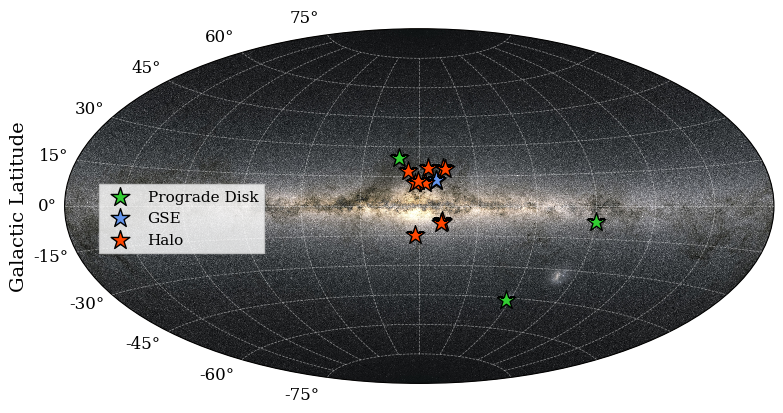

In [4]:

# setup a MWSkyMap instance with projection, other projection can be 'hammer', 'mollweide' etc
# grayscale: whether to turn the background image to grayscale
mw = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic')

# so that the colorbar will has a better contract
# plot_instance.clim = (5., 15.)
mw.imalpha = 1.

# # galactic longitude axis labels
# mw.set_ticklabel_visible(True)
# mw.set_axislabel('Galactic Longitude')
# # galactic lattitude axis labels
# mw.lat.set_ticklabel_visible(True)
# mw.lat.set_axislabel('Galactic Latitude')

# set up plot title
mw.s = 200
mw.figsize = (8, 6)
mw.fontsize = 12



# use mw_scatter instead of scatter
mw.mw_scatter(pro_disk['ra'].to_numpy() * u.degree, pro_disk['dec'].to_numpy() * u.degree, 'limegreen', label='Prograde Disk', marker='*', edgecolor = 'black')
mw.mw_scatter(gse['ra'].to_numpy() * u.degree, gse['dec'].to_numpy() * u.degree, 'cornflowerblue', label='GSE', marker='*', edgecolor = 'black')
mw.mw_scatter(halo['ra'].to_numpy() * u.degree, halo['dec'].to_numpy() * u.degree, 'orangered', label='Halo', marker='*', edgecolor = 'black')


mw.fig.legend(bbox_to_anchor=(0.35, 0.55), fancybox=False, fontsize=11)

# plt.xlabel('Galactic Longitude')
plt.ylabel('Galactic Latitude')
mw.fig.tight_layout()    

mw.fig.savefig('/data/misfit/benlowe/xshooter/results/mw_distribution/emp_dist_v2.pdf', dpi=300, transparent=False, facecolor='white', bbox_inches='tight')
# plot_instance.savefig(file='/data/mustard/benlowe/results/paper_plots/poster/aat_all_sky.png')

# Show the figure
mw.show()

Looking at the prograde disk located at SMC

In [7]:
# Open up pickle file
orb_file = pickle.load(open('/data/mustard/benlowe/data/orbit_data/aat_orbits/ra_0103-7050_orbits.pickle', 'rb'))
len(orb_file)

20

## For comparision literature stars

In [9]:
gaia_lit_df

,catalog,star_id,gaia_id,random_index,ra,dec,parallax,parallax_error,parallax_over_error,pmra,...,ebpminrp_gspphot,target_id,target_ra,target_dec,target_parallax,target_pm_ra,target_pm_dec,target_radial_velocity,epoch,target_separation (deg)
0,yong2013,52972-1213-507,811812182598263552,730540375,139.707938,37.740593,0.468856,0.039756,11.793310,-5.860822,...,0.0115,Gaia DR3 811812182598263552,139.707938,37.740593,0.4689,-5.8608,-33.2725,0.0000,2016.0,0.000000e+00
1,yong2013,53327-2044-515,290930261314166528,1215239180,25.150925,23.749406,1.066217,0.036955,28.851522,0.972496,...,0.2907,Gaia DR3 290930261314166528,25.150925,23.749406,1.0662,0.9725,-21.5905,0.0000,2016.0,0.000000e+00
2,yong2013,54142-2667-094,598558225898219776,772626430,132.902825,10.300841,0.422213,0.028656,14.734057,-8.773143,...,0.1108,Gaia DR3 598558225898219776,132.902825,10.300841,0.4222,-8.7731,-17.1661,0.0000,2016.0,1.776357e-15
3,yong2013,BS 16545-089,760839819965612928,344569189,171.114717,36.841186,0.644339,0.023748,27.132257,10.309770,...,0.0405,Gaia DR3 760839819965612928,171.114717,36.841186,0.6443,10.3098,-34.1174,0.0000,2016.0,0.000000e+00
4,yong2013,CS 30336-049,6795730493933072128,60677280,311.348047,-28.710012,0.062969,0.017374,3.624422,-1.727017,...,NaN,Gaia DR3 6795730493933072128,311.348047,-28.710012,0.0630,-1.7270,-8.1800,-235.8673,2016.0,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,yong2021,J224145.62-064643.0,2623363791014198656,990092424,340.440108,-6.778676,0.075457,0.018667,4.042358,1.869163,...,NaN,Gaia DR3 2623363791014198656,340.440108,-6.778676,0.0755,1.8692,-2.8984,-207.4769,2016.0,8.881784e-16
311,yong2021,J230525.31-213807.0,2398202677437168384,779426047,346.355546,-21.635311,0.286466,0.012346,23.202960,-1.075391,...,NaN,Gaia DR3 2398202677437168384,346.355546,-21.635311,0.2865,-1.0754,-15.1677,-17.3665,2016.0,0.000000e+00
312,yong2021,J230702.22-693718.5,6384594749521894400,286939962,346.759342,-69.621844,0.052283,0.015166,3.447462,1.060945,...,NaN,Gaia DR3 6384594749521894400,346.759342,-69.621844,0.0523,1.0609,-5.9018,153.2275,2016.0,0.000000e+00
313,yong2021,J232121.57-160505.4,2406023396270909440,605784975,350.339926,-16.084881,0.456265,0.013901,32.823170,17.221111,...,NaN,Gaia DR3 2406023396270909440,350.339926,-16.084881,0.4563,17.2211,3.4440,-40.4604,2016.0,0.000000e+00


In [8]:
lit_df = lit_df.drop_duplicates()
lit_df

,catalog,star_id,gaia_id,rv
0,yong2013,52972-1213-507,811812182598263552,-176.950000
1,yong2013,53327-2044-515,290930261314166528,-193.500000
2,yong2013,54142-2667-094,598558225898219776,43.400000
3,yong2013,BS 16545-089,760839819965612928,-161.166667
4,yong2013,CS 30336-049,6795730493933072128,-236.633333
...,...,...,...,...
333,yong2021,J224145.62-064643.0,2623363791014198656,-201.600000
334,yong2021,J230525.31-213807.0,2398202677437168384,-15.700000
335,yong2021,J230702.22-693718.5,6384594749521894400,173.900000
336,yong2021,J232121.57-160505.4,2406023396270909440,-39.100000


Loading in the data

In [2]:
gaia_lit_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_gaiadr3_final.csv')
gaia_lit_df.rename(columns={'source_id': 'gaia_id'}, inplace=True)
lit_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_rvs.csv')

comb_lit_df = pd.merge(lit_df[['gaia_id', 'catalog']], gaia_lit_df[['gaia_id', 'ra', 'dec']], on='gaia_id', how='inner')
comb_lit_df.drop_duplicates('gaia_id')

# Separating into different catalogs
yong2013_df = comb_lit_df[comb_lit_df['catalog'] == 'yong2013']
jacobson2015_df = comb_lit_df[comb_lit_df['catalog'] == 'jacobson2015']
marino2019_df = comb_lit_df[comb_lit_df['catalog'] == 'marino2019']
yong2021_df = comb_lit_df[comb_lit_df['catalog'] == 'yong2021']

In [68]:
lit_df[lit_df['catalog'] == 'marino2019']

,catalog,star_id,gaia_id,rv
161,marino2019,SMSS J202059.17-043447.0,6381793915449034624,-190.7
162,marino2019,SMSS J202400.03-024445.9,6381793915449034624,-133.8
163,marino2019,SMSS J202601.44-033002.5,6381793915449034624,-149.5
164,marino2019,SMSS J202659.41-031149.2,6381793915449034624,-199.1
165,marino2019,SMSS J204654.92-020409.2,6381793915449034624,-451.2
166,marino2019,SMSS J211657.83-012517.5,6381793915449034624,-155.4
167,marino2019,SMSS J212001.71-001158.6,6381793915449034624,-350.2
168,marino2019,SMSS J212113.63-005132.2,6381793915449034624,33.9
169,marino2019,SMSS J212217.52-295552.7,6381793915449034624,200.8
170,marino2019,SMSS J220514.10-013407.6,6381793915449034624,-199.2


Plotting

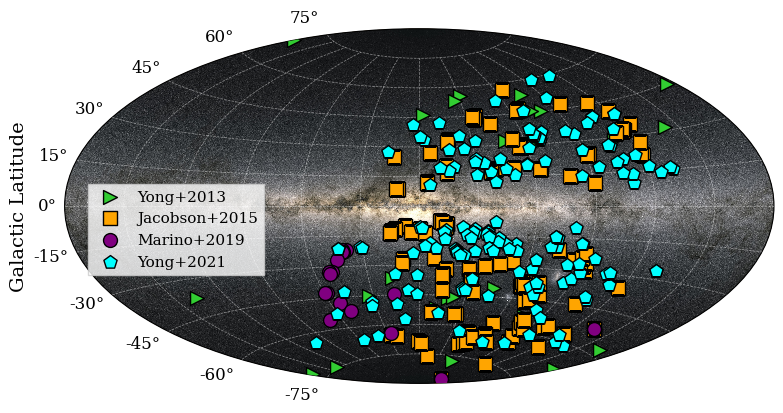

In [9]:
# setup a MWSkyMap instance with projection, other projection can be 'hammer', 'mollweide' etc
# grayscale: whether to turn the background image to grayscale
mw = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic')

# so that the colorbar will has a better contract
# plot_instance.clim = (5., 15.)
mw.imalpha = 1.

# # galactic longitude axis labels
# mw.set_ticklabel_visible(True)
# mw.set_axislabel('Galactic Longitude')
# # galactic lattitude axis labels
# mw.lat.set_ticklabel_visible(True)
# mw.lat.set_axislabel('Galactic Latitude')

# set up plot title
mw.s = 100
mw.figsize = (8, 6)
mw.fontsize = 12



# use mw_scatter instead of scatter
mw.mw_scatter(yong2013_df['ra'].to_numpy() * u.degree, yong2013_df['dec'].to_numpy() * u.degree, 'limegreen', label='Yong+2013', marker='>', edgecolor = 'black')
mw.mw_scatter(jacobson2015_df['ra'].to_numpy() * u.degree, jacobson2015_df['dec'].to_numpy() * u.degree, 'orange', label='Jacobson+2015', marker='s', edgecolor = 'black')
mw.mw_scatter(marino2019_df['ra'].to_numpy() * u.degree, marino2019_df['dec'].to_numpy() * u.degree, 'purple', label='Marino+2019', marker='o', edgecolor = 'black')
mw.mw_scatter(yong2021_df['ra'].to_numpy() * u.degree, yong2021_df['dec'].to_numpy() * u.degree, 'cyan', label='Yong+2021', marker='p', edgecolor = 'black')

mw.fig.legend(bbox_to_anchor=(0.35, 0.55), fancybox=False, fontsize=11)

# plt.xlabel('Galactic Longitude')
plt.ylabel('Galactic Latitude')
mw.fig.tight_layout()    

mw.fig.savefig('/data/misfit/benlowe/xshooter/p115/results/lit_results/lit_dist.pdf', dpi=300, transparent=False, facecolor='white', bbox_inches='tight')
# plot_instance.savefig(file='/data/mustard/benlowe/results/paper_plots/poster/aat_all_sky.png')

# Show the figure
mw.show()

In [10]:
marino2019_df

,gaia_id,catalog,ra,dec
166,4219173428310125824,marino2019,305.246575,-4.579780
167,4222838684680819456,marino2019,306.000124,-2.746122
168,4219733526404320512,marino2019,306.506028,-3.500737
169,4219749194445529856,marino2019,306.747551,-3.197042
170,4225198408431380480,marino2019,311.728830,-2.069251
171,2685826260609718656,marino2019,319.240974,-1.421576
172,2689381359659392512,marino2019,320.007151,-0.199645
173,2686326985076954624,marino2019,320.306796,-0.858983
174,6789177610788482688,marino2019,320.573027,-29.931372
175,2677118609553600512,marino2019,331.308790,-1.568829
